Dataset URL: https://www.kaggle.com/datasets/puneet6060/intel-image-classification
License(s): copyright-authors
intel-image-classification.zip: Skipping, found more recently modified local copy (use --force to force download)
buildings: 2191 images
forest: 2271 images
glacier: 2404 images
mountain: 2512 images
sea: 2274 images
street: 2382 images

Broken images: 0


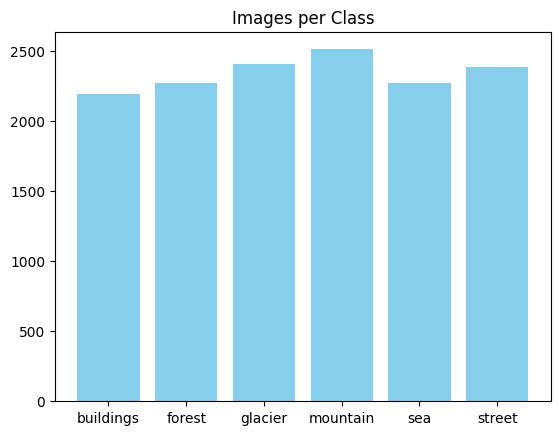

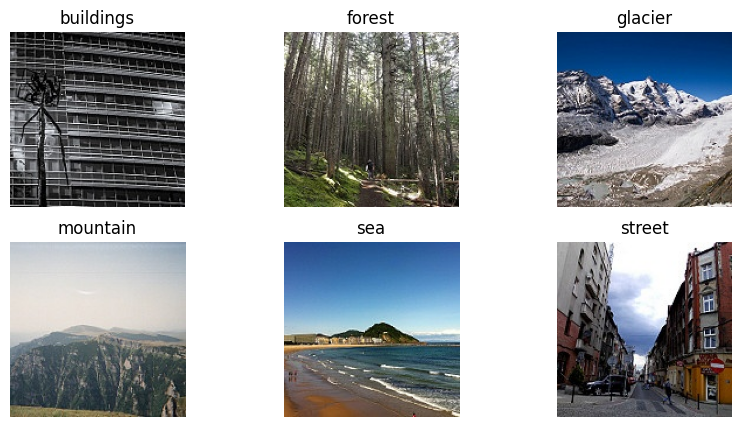

In [ ]:
import os, glob
from PIL import Image
import matplotlib.pyplot as plt

# download and unzip dataset folder
os.environ['KAGGLE_API_TOKEN'] = 'YOUR_KAGGLE_API_TOKEN'
!kaggle datasets download -d puneet6060/intel-image-classification
!unzip -oq intel-image-classification.zip -d intel_data

# count images and also check for broken images
train_dir = 'intel_data/seg_train/seg_train'
classes = sorted(os.listdir(train_dir))
counts, broken = [], 0

for c in classes:
    files = glob.glob(f"{train_dir}/{c}/*.jpg")
    good = 0
    for f in files:
        try:
            Image.open(f).verify()
            good += 1
        except:
            broken += 1
    counts.append(good)
    print(f"{c}: {good} images")

print(f"\nBroken images: {broken}")

# draw bar chart
plt.bar(classes, counts, color='skyblue')
plt.title("Images per Class")
plt.show()

# show 1 sample picture from each of the 6 classes
plt.figure(figsize=(10, 5))
for i, c in enumerate(classes):
    first_img = glob.glob(f"{train_dir}/{c}/*.jpg")[0]
    plt.subplot(2, 3, i + 1)
    plt.imshow(Image.open(first_img))
    plt.title(c)
    plt.axis('off')
plt.show()